# Semantic Segmentation: Which Pixels Are People?

This notebook goes with the lecture on semantic segmentation. A classifier gives one answer per photo. Here the network gives one answer **per pixel**: person or background.

1. Lecture 09's way (k-means on colors), scored against hand-drawn masks.
2. A network somebody else trained, and what its output looks like: one score map per class.
3. How to score a segmentation, and why pixel accuracy flatters a bad one.
4. The lecture's upsampling examples in PyTorch, including the transposed convolution.
5. Our own segmentation network: Lecture 15's **ResNet-18** as the encoder, and three ways of getting back to full size. The third is a **U-Net**.

The data is the **Penn-Fudan Database for Pedestrian Detection and Segmentation** (Wang, Shi, Song and Shen, 2007): 170 street photos from two campuses, with a mask for every pedestrian. The code below downloads it (51 MB) into `data/PennFudanPed/` the first time, and the pretrained weights (45 MB and 135 MB) into PyTorch's cache.

Running time: about 5 minutes with a GPU, about 25 minutes on a laptop CPU (nearly all of it in the three training runs). Every run is seeded, but the numbers still change a little from one computer to another.

In [1]:
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2 as cv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt
from PIL import Image
from torchvision import models

# A GPU if there is one: NVIDIA (cuda), Apple silicon (mps), otherwise the CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('device:', device)

device: cuda


## The Data: Penn-Fudan Pedestrians

Every photo `PNGImages/X.png` has a mask `PedMasks/X_mask.png` of the same size. The mask is not a picture: its pixel values are **labels**. 0 means background, 1 the first pedestrian, 2 the second, and so on.

In [2]:
root = Path('data/PennFudanPed')
if not root.exists():
    root.parent.mkdir(exist_ok=True)
    archive = root.parent / 'PennFudanPed.zip'
    urllib.request.urlretrieve('https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip', archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(root.parent)
    archive.unlink()

files = sorted((root / 'PNGImages').glob('*.png'))
print(len(files), 'photos')

def read_photo(i):
    return cv.cvtColor(cv.imread(str(files[i])), cv.COLOR_BGR2RGB)      # OpenCV reads BGR

def read_mask(i):
    return cv.imread(str(root / 'PedMasks' / (files[i].stem + '_mask.png')), cv.IMREAD_GRAYSCALE)

photo, mask = read_photo(0), read_mask(0)
print('photo:', photo.shape, photo.dtype, '  mask:', mask.shape, mask.dtype, '  values in the mask:', np.unique(mask))

170 photos
photo: (536, 559, 3) uint8   mask: (536, 559) uint8   values in the mask: [0 1 2]


The mask says more than we need today. It tells the pedestrians apart (**instance segmentation**). Semantic segmentation only asks which class each pixel belongs to, so `mask > 0` is our ground truth: 1 for person, 0 for background. We come back to the difference at the end.

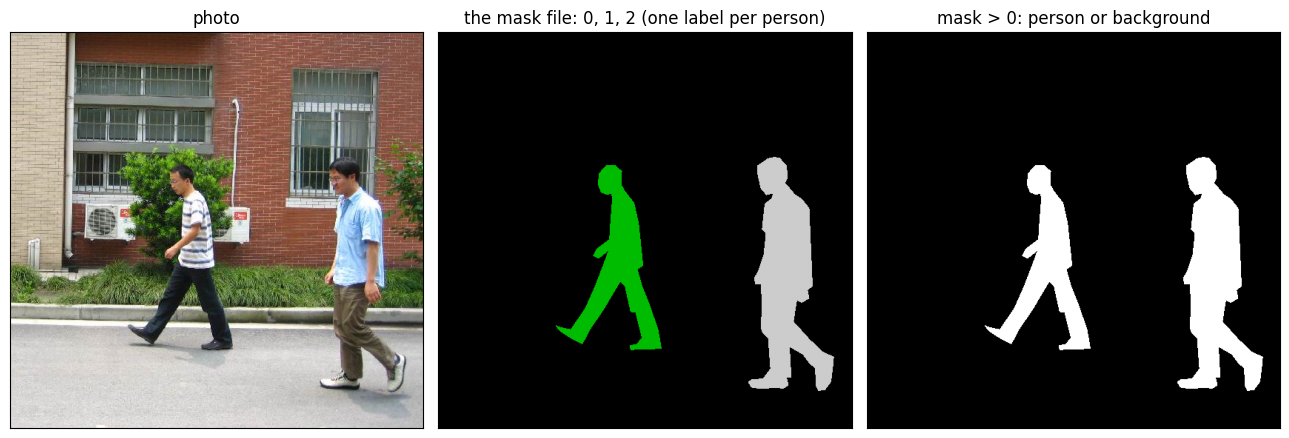

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
axs[0].imshow(photo); axs[0].set_title('photo')
axs[1].imshow(mask, cmap='nipy_spectral'); axs[1].set_title('the mask file: 0, 1, 2 (one label per person)')
axs[2].imshow(mask > 0, cmap='gray'); axs[2].set_title('mask > 0: person or background')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

The photos have different sizes. We resize all of them to 256 × 256 so they can be stacked into one tensor (pedestrians get a little wider or narrower, which does not matter here). **The mask must be resized with nearest-neighbor interpolation**: bilinear interpolation would invent label values such as 0.5, halfway between background and person 1.

120 photos are for training and 50 for testing, drawn at random with a fixed seed.

In [4]:
SIZE = 256
X = np.stack([cv.resize(read_photo(i), (SIZE, SIZE), interpolation=cv.INTER_AREA) for i in range(len(files))])
Y = np.stack([cv.resize((read_mask(i) > 0).astype(np.uint8), (SIZE, SIZE), interpolation=cv.INTER_NEAREST) for i in range(len(files))])
X = torch.from_numpy(X).permute(0, 3, 1, 2)          # (170, 3, 256, 256), uint8, RGB
Y = torch.from_numpy(Y).long()                       # (170, 256, 256), 0 or 1

order = torch.randperm(len(files), generator=torch.Generator().manual_seed(0))
train_idx, test_idx = order[:120], order[120:]
print('X:', tuple(X.shape), ' Y:', tuple(Y.shape))
print(f'person pixels: {Y.float().mean():.1%} of all pixels, {Y[test_idx].float().mean():.1%} of the test pixels')
print(f'RESULT person_fraction_test: {Y[test_idx].float().mean():.4f}')

X: (170, 3, 256, 256)  Y: (170, 256, 256)
person pixels: 17.3% of all pixels, 17.8% of the test pixels
RESULT person_fraction_test: 0.1777


## Scoring a Segmentation: Pixel Accuracy and IoU

**Pixel accuracy** is the fraction of pixels labeled correctly. **Intersection over union (IoU)** looks at one class: of all the pixels that the prediction or the truth call "person", what fraction do both call "person"?

IoU = (predicted person AND truly person) / (predicted person OR truly person)

It is 1 for a perfect mask and 0 for a mask that misses the person entirely. Both functions below count over all the photos they are given.

In [5]:
def pixel_accuracy(pred, truth):
    return (pred == truth).float().mean().item()

def iou(pred, truth):
    intersection = ((pred == 1) & (truth == 1)).sum().item()
    union = ((pred == 1) | (truth == 1)).sum().item()
    return intersection / union if union else 1.0

truth = Y[test_idx]
nobody = torch.zeros_like(truth)                     # a "segmentation" that says background everywhere
print(f'all background:  pixel accuracy {pixel_accuracy(nobody, truth):.1%}   IoU {iou(nobody, truth):.2f}')
print(f'RESULT background_accuracy: {pixel_accuracy(nobody, truth):.4f}')

all background:  pixel accuracy 82.2%   IoU 0.00
RESULT background_accuracy: 0.8223


A program that never finds anybody is right about four pixels out of five, because four pixels out of five are background. Its IoU is 0. **When one class is rare, pixel accuracy says little; report IoU.**

## Lecture 09's Way: Group Pixels by Color

In Lecture 09 we segmented with k-means: every pixel is a point in color space, and pixels with similar colors get the same label. Here it is with K = 3 on a test photo.

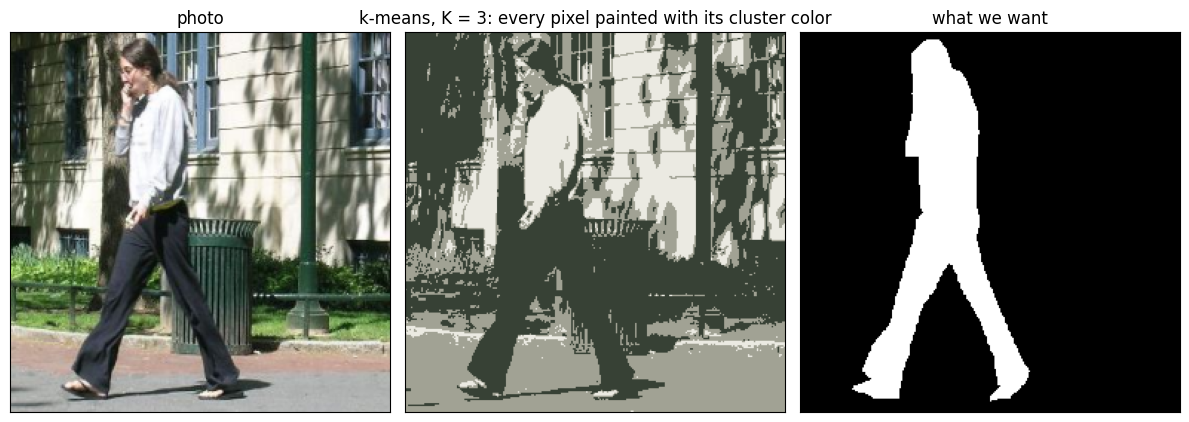

In [6]:
def kmeans_labels(rgb, K=3):
    pixels = rgb.reshape(-1, 3).astype(np.float32)
    criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    cv.setRNGSeed(0)
    _, labels, centers = cv.kmeans(pixels, K, None, criteria, 3, cv.KMEANS_PP_CENTERS)
    return labels.reshape(rgb.shape[:2]), centers

SHOW = [int(test_idx[k]) for k in (7, 21, 4, 30)]    # four test photos used for the pictures below
i = SHOW[0]
rgb = X[i].permute(1, 2, 0).numpy()
labels, centers = kmeans_labels(rgb)
fig, axs = plt.subplots(1, 3, figsize=(12, 4.3))
axs[0].imshow(rgb); axs[0].set_title('photo')
axs[1].imshow(centers[labels].astype(np.uint8)); axs[1].set_title('k-means, K = 3: every pixel painted with its cluster color')
axs[2].imshow(Y[i], cmap='gray'); axs[2].set_title('what we want')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

K-means does not know which cluster is "person". Let us be generous and, for every test photo, pick the cluster that overlaps the true mask best (something we could never do on a new photo, because we would not have its mask).

In [7]:
best = []
for i in test_idx.tolist():
    labels, _ = kmeans_labels(X[i].permute(1, 2, 0).numpy())
    masks = [torch.from_numpy((labels == k).astype(np.int64)) for k in range(3)]
    best.append(max(masks, key=lambda m: iou(m, Y[i])))
best = torch.stack(best)
print(f'k-means, best cluster per photo:  pixel accuracy {pixel_accuracy(best, truth):.1%}   IoU {iou(best, truth):.2f}')
print(f'RESULT kmeans_iou: {iou(best, truth):.4f}')
print(f'RESULT kmeans_accuracy: {pixel_accuracy(best, truth):.4f}')

k-means, best cluster per photo:  pixel accuracy 68.4%   IoU 0.22
RESULT kmeans_iou: 0.2245
RESULT kmeans_accuracy: 0.6838


Even with that help the IoU is low. A person is not a color: a dark coat is grouped with a dark doorway, and a face with a wall. Grouping needs to know **what things are**, and that is what a CNN learns.

## A Network That Already Knows People

`torchvision` ships segmentation networks trained by others. `fcn_resnet50` is a **fully convolutional network** with a ResNet-50 inside, trained on photos labeled with 20 object classes plus background. As in Lecture 15, the weights come with the preprocessing they expect.

In [8]:
weights = models.segmentation.FCN_ResNet50_Weights.DEFAULT
fcn = models.segmentation.fcn_resnet50(weights=weights).eval().to(device)
fcn_classes = weights.meta['categories']
fcn_transforms = weights.transforms()
print(len(fcn_classes), 'classes:', ', '.join(fcn_classes))
print(fcn_transforms)

21 classes: __background__, aeroplane, bicycle, bird, boat, bottle, bus, car, cat, chair, cow, diningtable, dog, horse, motorbike, person, pottedplant, sheep, sofa, train, tvmonitor
SemanticSegmentation(
    resize_size=[520]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


A classifier turns a photo into one row of class scores. This network turns a photo into **one score map per class**, each as large as the photo: a tensor of shape (21, H, W). The prediction for a pixel is the class whose map is highest there (`argmax` over the class dimension).

input: (1, 3, 520, 559)   scores: (21, 520, 559)   prediction: (520, 559)
classes found: ['__background__', 'bicycle', 'person']


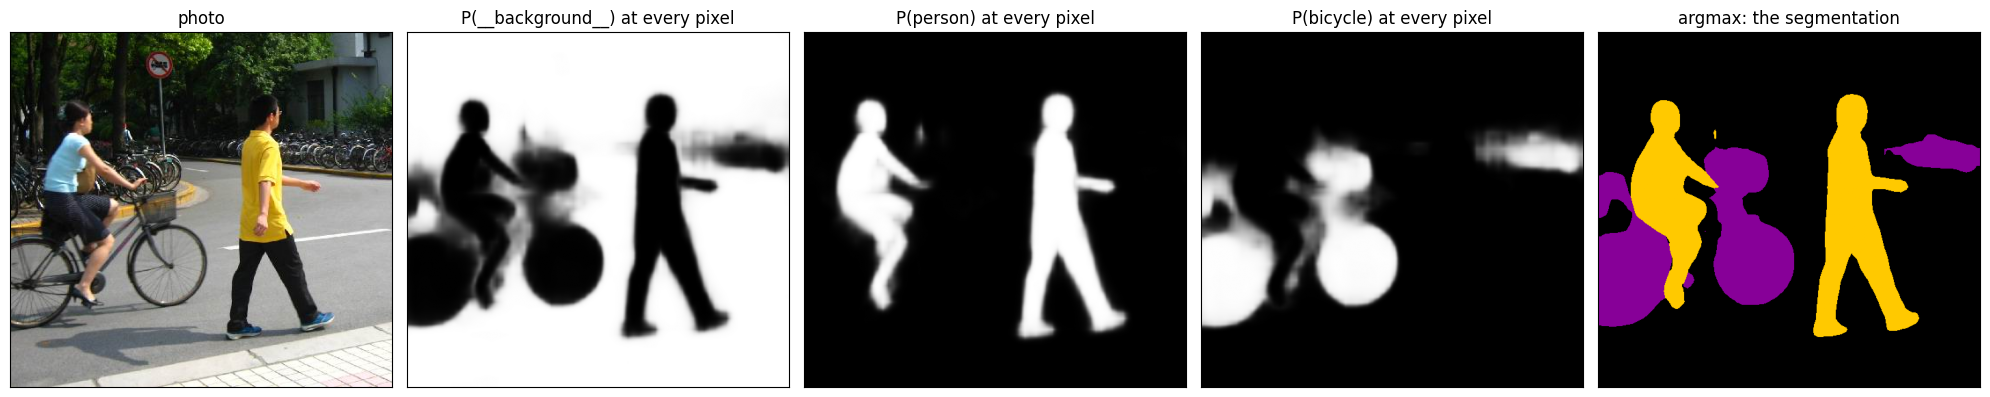

In [9]:
FCN_DEMO = int(test_idx[6])                         # a test photo with more in it than pedestrians
pil = Image.open(files[FCN_DEMO]).convert('RGB')
x = fcn_transforms(pil).unsqueeze(0).to(device)     # (1, 3, H, W): resized so the shorter side is 520, normalized
with torch.no_grad():
    scores = fcn(x)['out'][0]                        # (21, H, W)
probs = F.softmax(scores, dim=0).cpu()               # softmax over the 21 classes, separately at every pixel
prediction = probs.argmax(0)                         # (H, W): one class number per pixel
print('input:', tuple(x.shape), '  scores:', tuple(scores.shape), '  prediction:', tuple(prediction.shape))
print('classes found:', [fcn_classes[k] for k in prediction.unique().tolist()])

person = fcn_classes.index('person')
others = [k for k in prediction.unique().tolist() if k not in (0, person)]
show = [0, person] + sorted(others, key=lambda k: -(prediction == k).sum().item())[:1]
fig, axs = plt.subplots(1, len(show) + 2, figsize=(4 * (len(show) + 2), 4.2))
axs[0].imshow(pil); axs[0].set_title('photo')
for ax, k in zip(axs[1:], show):
    ax.imshow(probs[k], cmap='gray', vmin=0, vmax=1); ax.set_title(f'P({fcn_classes[k]}) at every pixel')
axs[-1].imshow(prediction, cmap='nipy_spectral', vmin=0, vmax=20); axs[-1].set_title('argmax: the segmentation')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Nobody trained this network on our photos, yet it finds the people, and the bicycle. Notice that it marks the cyclist as a person too. The dataset's mask does not: its authors labeled pedestrians only. **A segmentation is scored against somebody's decision about what counts.** Here is the network on all 50 test photos. Its person mask is resized to 256 × 256 (nearest neighbor) to compare it with our ground truth.

In [10]:
def fcn_person_probability(i):                       # all 21 probability maps of photo i
    x = fcn_transforms(Image.open(files[i]).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        p = F.softmax(fcn(x)['out'], dim=1)
    return p[0].cpu()

fcn_pred = []
for i in test_idx.tolist():
    p = fcn_person_probability(i)
    m = (p.argmax(0) == person).numpy().astype(np.uint8)
    fcn_pred.append(torch.from_numpy(cv.resize(m, (SIZE, SIZE), interpolation=cv.INTER_NEAREST)).long())
fcn_pred = torch.stack(fcn_pred)
print(f'pretrained FCN:  pixel accuracy {pixel_accuracy(fcn_pred, truth):.1%}   IoU {iou(fcn_pred, truth):.2f}')
print(f'RESULT fcn_iou: {iou(fcn_pred, truth):.4f}')
print(f'RESULT fcn_accuracy: {pixel_accuracy(fcn_pred, truth):.4f}')
print(f'RESULT fcn_params: {sum(p.numel() for p in fcn.parameters())}')
fcn = fcn.cpu()                                      # free the GPU for the training below

pretrained FCN:  pixel accuracy 95.6%   IoU 0.79
RESULT fcn_iou: 0.7918
RESULT fcn_accuracy: 0.9557
RESULT fcn_params: 35322218


## Upsampling in PyTorch

A CNN shrinks its input: ResNet-18 turns 256 × 256 pixels into an 8 × 8 feature map. A segmentation needs an answer for every pixel, so the network must also **upsample**. These are the lecture's examples, on the same 2 × 2 input.

In [11]:
x = torch.tensor([[1., 2.],
                  [3., 4.]]).view(1, 1, 2, 2)           # (batch, channels, height, width)

print('nearest neighbor:')
print(F.interpolate(x, scale_factor=2, mode='nearest')[0, 0])
print('bilinear:')
print(F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)[0, 0])

nearest neighbor:
tensor([[1., 1., 2., 2.],
        [1., 1., 2., 2.],
        [3., 3., 4., 4.],
        [3., 3., 4., 4.]])
bilinear:
tensor([[1.0000, 1.2500, 1.7500, 2.0000],
        [1.5000, 1.7500, 2.2500, 2.5000],
        [2.5000, 2.7500, 3.2500, 3.5000],
        [3.0000, 3.2500, 3.7500, 4.0000]])


Neither of these has anything to learn. A **transposed convolution** does: every input value is multiplied by the whole filter, and the result is pasted into the output, `stride` pixels apart. Where the pasted copies overlap, they are added.

With a 2 × 2 filter and stride 2 the copies do not overlap. If the filter is all ones, the layer is exactly nearest-neighbor upsampling.

In [12]:
up = nn.ConvTranspose2d(1, 1, kernel_size=2, stride=2, bias=False)
with torch.no_grad():
    up.weight.fill_(1.0)
    print(up(x)[0, 0])

tensor([[1., 1., 2., 2.],
        [1., 1., 2., 2.],
        [3., 3., 4., 4.],
        [3., 3., 4., 4.]])


With a 3 × 3 filter and stride 2 the copies overlap by one pixel. The output is 5 × 5, and the overlapping row and column hold sums: the center is 1 + 2 + 3 + 4 = 10.

In [13]:
up = nn.ConvTranspose2d(1, 1, kernel_size=3, stride=2, bias=False)
with torch.no_grad():
    up.weight.fill_(1.0)
    print(up(x)[0, 0])

# padding=1 trims one pixel all around and output_padding=1 adds one back at the bottom and right: exactly 2 x the input
up = nn.ConvTranspose2d(1, 1, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False)
print('with padding=1, output_padding=1:', tuple(up(x).shape))

tensor([[ 1.,  1.,  3.,  2.,  2.],
        [ 1.,  1.,  3.,  2.,  2.],
        [ 4.,  4., 10.,  6.,  6.],
        [ 3.,  3.,  7.,  4.,  4.],
        [ 3.,  3.,  7.,  4.,  4.]])
with padding=1, output_padding=1: (1, 1, 4, 4)


In a network the filter values are not ones: they are **learned** by gradient descent like every other weight. The network decides how to upsample.

## Our Own Network: ResNet-18 and Three Ways Back Up

The **encoder** is the pretrained ResNet-18 of Lecture 15, without its average pooling and its `fc` layer. It halves the resolution five times:

In [14]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
x = torch.zeros(1, 3, SIZE, SIZE)
print(f'{"input":28s} {tuple(x.shape)}')
x = resnet.relu(resnet.bn1(resnet.conv1(x))); print(f'{"conv1 (stride 2)":28s} {tuple(x.shape)}')
x = resnet.layer1(resnet.maxpool(x));         print(f'{"maxpool, layer1":28s} {tuple(x.shape)}')
x = resnet.layer2(x);                         print(f'{"layer2":28s} {tuple(x.shape)}')
x = resnet.layer3(x);                         print(f'{"layer3":28s} {tuple(x.shape)}')
x = resnet.layer4(x);                         print(f'{"layer4":28s} {tuple(x.shape)}')

input                        (1, 3, 256, 256)
conv1 (stride 2)             (1, 64, 128, 128)


maxpool, layer1              (1, 64, 64, 64)


layer2                       (1, 128, 32, 32)
layer3                       (1, 256, 16, 16)
layer4                       (1, 512, 8, 8)


After `layer4` there are 512 feature maps of 8 × 8: each position summarizes a 32 × 32 block of the photo. Three networks share this encoder and differ only in how they return to 256 × 256:

- **`coarse`**: a 1 × 1 convolution turns the 512 features into 2 scores (background, person) at each of the 8 × 8 positions, and one bilinear step enlarges the two score maps 32 times. This is Lecture 14's fully convolutional classifier, enlarged.
- **`decoder`**: five transposed convolutions (each doubles the size), with a 3 × 3 convolution after each of the first four.
- **`unet`**: the same decoder, but after each of the first four transposed convolutions the encoder's feature maps of the same size are **concatenated** to the decoder's (`torch.cat` along the channel dimension). These are the **skip connections** of a U-Net.

In [15]:
class Segmenter(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        r = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)                  # 64 maps, 1/2 size
        self.pool = r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        if kind == 'coarse':
            self.head = nn.Conv2d(512, 2, kernel_size=1)
        else:
            channels = [512, 256, 128, 64, 64]
            skip = [256, 128, 64, 64] if kind == 'unet' else [0, 0, 0, 0]  # channels arriving over each skip connection
            self.up = nn.ModuleList([nn.ConvTranspose2d(channels[k], channels[k + 1], kernel_size=2, stride=2) for k in range(4)])
            self.conv = nn.ModuleList([nn.Sequential(nn.Conv2d(channels[k + 1] + skip[k], channels[k + 1], kernel_size=3, padding=1),
                                                     nn.BatchNorm2d(channels[k + 1]), nn.ReLU()) for k in range(4)])
            self.last_up = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
            self.head = nn.Conv2d(32, 2, kernel_size=1)

    def forward(self, x):
        f0 = self.stem(x)                    # 1/2
        f1 = self.layer1(self.pool(f0))      # 1/4
        f2 = self.layer2(f1)                 # 1/8
        f3 = self.layer3(f2)                 # 1/16
        f4 = self.layer4(f3)                 # 1/32
        if self.kind == 'coarse':
            return F.interpolate(self.head(f4), scale_factor=32, mode='bilinear', align_corners=False)
        y = f4
        for k, from_encoder in enumerate([f3, f2, f1, f0]):
            y = self.up[k](y)                                # twice the size
            if self.kind == 'unet':
                y = torch.cat([y, from_encoder], dim=1)      # the skip connection
            y = self.conv[k](y)
        return self.head(self.last_up(y))    # (batch, 2, 256, 256): a background map and a person map

for kind in ('coarse', 'decoder', 'unet'):
    net = Segmenter(kind)
    out = net(torch.zeros(1, 3, SIZE, SIZE))
    print(f'{kind:8s} output {tuple(out.shape)}   parameters {sum(p.numel() for p in net.parameters()):,}')
    print(f'RESULT params_{kind}: {sum(p.numel() for p in net.parameters())}')

coarse   output (1, 2, 256, 256)   parameters 11,177,538
RESULT params_coarse: 11177538


decoder  output (1, 2, 256, 256)   parameters 12,702,370
RESULT params_decoder: 12702370


unet     output (1, 2, 256, 256)   parameters 13,513,378
RESULT params_unet: 13513378


## Training: Cross-Entropy at Every Pixel

The loss is the cross-entropy of Lecture 13, computed **at every pixel** and averaged. `F.cross_entropy` does this by itself when the scores have shape (batch, classes, H, W) and the labels have shape (batch, H, W).

As in Lecture 15, the pretrained encoder is fine-tuned with a small learning rate (0.0001) and the new layers get a larger one (0.001). The only augmentation is a horizontal flip, which **must be applied to the photo and to its mask together**.

In [16]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prepare(batch_uint8):
    return ((batch_uint8.float() / 255 - MEAN) / STD).to(device)       # what the pretrained ResNet-18 expects

def train(kind, epochs=20, batch=8, seed=0):
    torch.manual_seed(seed)
    net = Segmenter(kind).to(device)
    encoder = [p for name, p in net.named_parameters() if name.split('.')[0] in ('stem', 'layer1', 'layer2', 'layer3', 'layer4')]
    new = [p for name, p in net.named_parameters() if name.split('.')[0] not in ('stem', 'layer1', 'layer2', 'layer3', 'layer4')]
    optimizer = torch.optim.Adam([{'params': encoder, 'lr': 1e-4}, {'params': new, 'lr': 1e-3}])
    g = torch.Generator().manual_seed(seed)
    for epoch in range(epochs):
        net.train()
        shuffled = train_idx[torch.randperm(len(train_idx), generator=g)]
        total = 0.0
        for start in range(0, len(shuffled), batch):
            idx = shuffled[start:start + batch]
            x, y = X[idx], Y[idx]
            if torch.rand(1, generator=g) < 0.5:             # flip the photos and their masks together
                x, y = x.flip(3), y.flip(2)
            loss = F.cross_entropy(net(prepare(x)), y.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        if epoch in (0, epochs // 2 - 1, epochs - 1):
            print(f'  {kind}: epoch {epoch + 1:2d}, training loss {total / len(shuffled):.3f}')
    return net

def person_probability(net, idx):
    net.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(idx), 10):
            out.append(F.softmax(net(prepare(X[idx[start:start + 10]])), dim=1)[:, 1].cpu())
    return torch.cat(out)                                    # (photos, 256, 256): P(person) at every pixel

In [17]:
prob = {}
for kind in ('coarse', 'decoder', 'unet'):
    start = time.time()
    net = train(kind)
    prob[kind] = person_probability(net, test_idx)
    pred = (prob[kind] > 0.5).long()                         # with two classes, argmax is the same as P(person) > 0.5
    print(f'{kind:8s} pixel accuracy {pixel_accuracy(pred, truth):.1%}   IoU {iou(pred, truth):.3f}   ({time.time() - start:.0f} s)')
    print(f'RESULT {kind}_iou: {iou(pred, truth):.4f}')
    print(f'RESULT {kind}_accuracy: {pixel_accuracy(pred, truth):.4f}')


  coarse: epoch  1, training loss 0.364


  coarse: epoch 10, training loss 0.171


  coarse: epoch 20, training loss 0.156
coarse   pixel accuracy 89.9%   IoU 0.536   (60 s)
RESULT coarse_iou: 0.5362
RESULT coarse_accuracy: 0.8995


  decoder: epoch  1, training loss 0.552


  decoder: epoch 10, training loss 0.129


  decoder: epoch 20, training loss 0.091


decoder  pixel accuracy 92.9%   IoU 0.664   (94 s)
RESULT decoder_iou: 0.6636
RESULT decoder_accuracy: 0.9286


  unet: epoch  1, training loss 0.467


  unet: epoch 10, training loss 0.058


  unet: epoch 20, training loss 0.039


unet     pixel accuracy 95.5%   IoU 0.772   (90 s)
RESULT unet_iou: 0.7722
RESULT unet_accuracy: 0.9549


All three find the pedestrians: the encoder already knows what people look like. The differences are at the **boundaries**. Remember the baseline: saying "background" everywhere already scores about 82% pixel accuracy, so the pixel accuracies above are closer together than the networks really are.

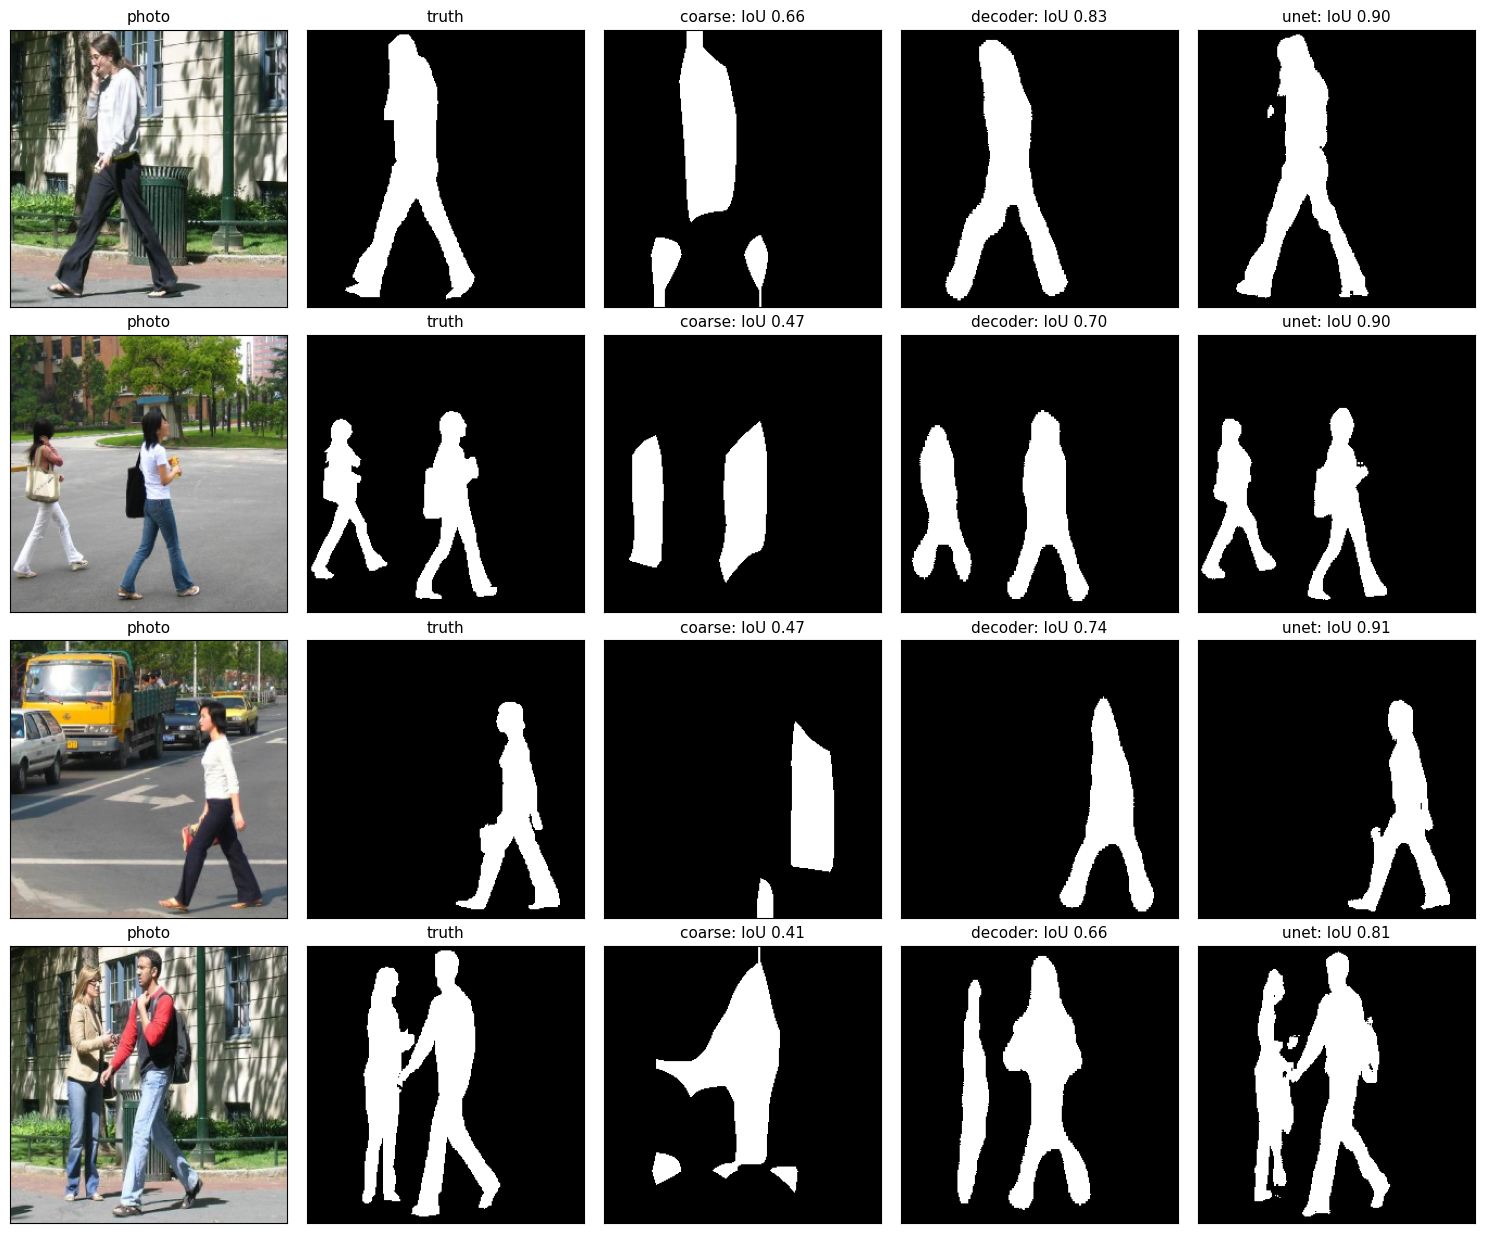

In [18]:
fig, axs = plt.subplots(len(SHOW), 5, figsize=(15, 3.1 * len(SHOW)))
for row, i in enumerate(SHOW):
    k = test_idx.tolist().index(i)
    panels = [('photo', X[i].permute(1, 2, 0)), ('truth', Y[i])] + [(kind, prob[kind][k] > 0.5) for kind in ('coarse', 'decoder', 'unet')]
    for ax, (name, img) in zip(axs[row], panels):
        ax.imshow(img, cmap='gray')
        title = name if name in ('photo', 'truth') else f'{name}: IoU {iou((prob[name][k] > 0.5).long(), Y[i]):.2f}'
        ax.set_title(title, fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

`coarse` has 8 × 8 = 64 decisions to spend on the whole photo, so its masks are blobs. `decoder` produces a full-size mask, but everything it knows about the photo has passed through the 8 × 8 bottleneck, where the exact position of an edge is lost. `unet` gets the encoder's early, high-resolution feature maps handed across, and with them the edges: legs separate, and outlines follow the bodies.

## What Semantic Segmentation Cannot Do

The dataset's masks number the pedestrians. A semantic segmentation only says "person". Can we count people by counting the connected blobs of a mask (Lecture 04's connected components)? Try it on the **hand-drawn** masks first: they are the best any semantic segmentation could do.

133 pedestrians in the 50 test photos
108 blobs in the hand-drawn masks: the count is right in 32 of 50 photos
120 blobs in the U-Net masks:     the count is right in 24 of 50 photos
RESULT people: 133
RESULT true_blobs: 108
RESULT true_count_right: 32
RESULT unet_blobs: 120
RESULT unet_count_right: 24


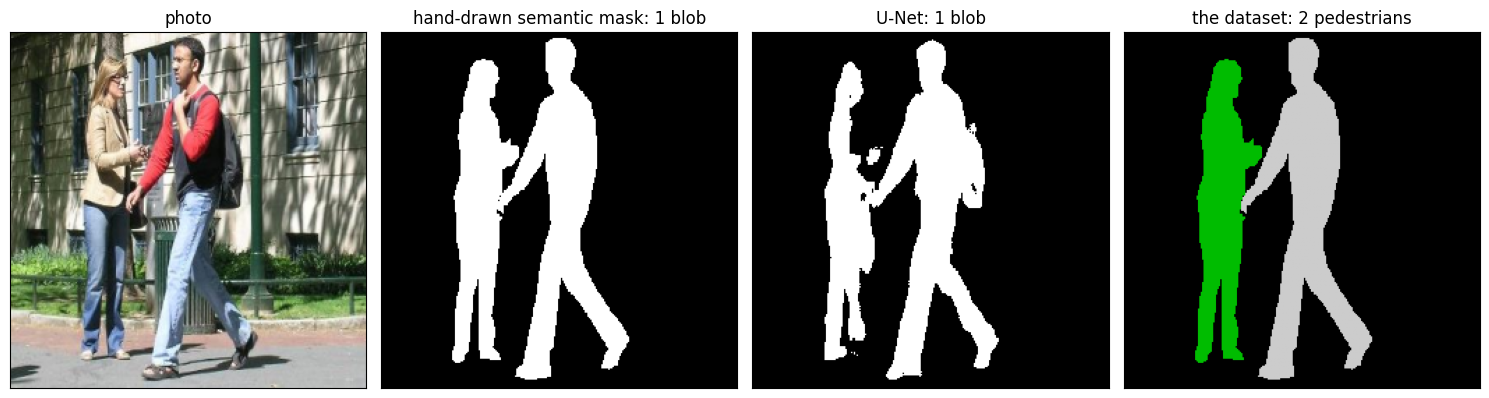

In [19]:
def count_blobs(mask, smallest=150):
    n, _, stats, _ = cv.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    return int((stats[1:, cv.CC_STAT_AREA] >= smallest).sum())           # row 0 is the background

people = np.array([len(np.unique(read_mask(i))) - 1 for i in test_idx.tolist()])
true_blobs = np.array([count_blobs(Y[i].numpy()) for i in test_idx.tolist()])
unet_blobs = np.array([count_blobs((prob['unet'][k] > 0.5).numpy()) for k in range(len(test_idx))])
print(f'{people.sum()} pedestrians in the 50 test photos')
print(f'{true_blobs.sum()} blobs in the hand-drawn masks: the count is right in {(people == true_blobs).sum()} of 50 photos')
print(f'{unet_blobs.sum()} blobs in the U-Net masks:     the count is right in {(people == unet_blobs).sum()} of 50 photos')
print(f'RESULT people: {people.sum()}')
print(f'RESULT true_blobs: {true_blobs.sum()}')
print(f'RESULT true_count_right: {(people == true_blobs).sum()}')
print(f'RESULT unet_blobs: {unet_blobs.sum()}')
print(f'RESULT unet_count_right: {(people == unet_blobs).sum()}')

i = SHOW[3]
k = test_idx.tolist().index(i)
fig, axs = plt.subplots(1, 4, figsize=(15, 4.2))
axs[0].imshow(X[i].permute(1, 2, 0)); axs[0].set_title('photo')
axs[1].imshow(Y[i], cmap='gray'); axs[1].set_title(f'hand-drawn semantic mask: {true_blobs[k]} blob')
axs[2].imshow(prob['unet'][k] > 0.5, cmap='gray'); axs[2].set_title(f'U-Net: {unet_blobs[k]} blob')
axs[3].imshow(cv.resize(read_mask(i), (SIZE, SIZE), interpolation=cv.INTER_NEAREST), cmap='nipy_spectral'); axs[3].set_title(f'the dataset: {people[k]} pedestrians')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Where pedestrians touch or overlap, their pixels merge into one blob. Every one of those pixels is correctly labeled "person", and nothing in the output says where one person ends and the next begins. Telling objects apart needs a different kind of output: a **box** (or a mask) **per object**. That is object detection, the next module, and its notebook uses these same photos.

In [20]:
out = Path('output')
out.mkdir(exist_ok=True)
np.savez_compressed(out / 'pedestrian_segmentation.npz', test_idx=test_idx.numpy(), show=np.array(SHOW),
                    **{kind: (prob[kind] * 255).round().byte().numpy() for kind in prob},
                    fcn_pred=fcn_pred.byte().numpy(), kmeans=best.byte().numpy(),
                    fcn_demo=np.array(FCN_DEMO), fcn_demo_probs=(probs * 255).round().byte().numpy())
print('saved the probability maps of the test photos to', out / 'pedestrian_segmentation.npz')

saved the probability maps of the test photos to output/pedestrian_segmentation.npz


## Try It Yourself

1. Keep the trained network (`unet = train('unet')`) and segment a photo of your own with it (resize it to 256 × 256 and use `prepare`). Then try a photo unlike the training photos: people sitting, a crowd, a night scene. Where does it fail, and why would 120 daytime photos from two campuses not prepare it for that?
2. Change the threshold in `prob['unet'] > 0.5` to 0.2 and to 0.8. What happens to the masks and to the IoU?
3. Replace the transposed convolutions of `decoder` by `nn.Upsample(scale_factor=2, mode='bilinear')` followed by a 3 × 3 convolution. Does the IoU change?
4. Give `unet` only the last skip connection (the one from `stem`), or only the first (from `layer3`). Which matters more for the boundaries?
5. Freeze the encoder (`requires_grad = False`, as in Lecture 15) and train only the new layers. How much IoU does fine-tuning the encoder buy?
6. Train `unet` with `models.resnet18(weights=None)`: no pretraining. How far do 120 photos get a network that has never seen a person?